# NeRF (Nerfacto) — bear-mask

Trains Nerfstudio's **nerfacto** on the masked bear capture and saves the model, rendered
comparisons and training metrics to Google Drive.

**Before running**
1. *Runtime → Change runtime type →* a **GPU** (T4 works; L4/A100 is faster).
2. Upload `data/nerfstudio/bear-mask.zip` from the repo to **`MyDrive/3d-reconstruction/bear-mask.zip`**
   (upload the zip as-is, don't unzip it). It was produced locally by `scripts/prepare_nerfstudio.py` from the
   undistorted COLMAP model (`colmap/bear-mask/dense/0`): 87 images at 1600×1062, stored as RGBA PNGs whose
   alpha is the rembg mask warped into the undistorted camera, plus `transforms.json` and `sparse_pc.ply`.
3. Run the cells top to bottom. **Section 2 restarts the Python kernel once after installing** (this is
   intended). Then continue from section 3. Every shell command is echoed
   and appended to a log on Drive, and each stage checks its outputs before moving on.

**Settings shared with the other notebook (keep them identical for a fair comparison)**
`--pipeline.model.background-color white` (the alpha matte is composited onto white),
`nerfstudio-data --downscale-factor 1 --eval-mode interval --eval-interval 8`
(every 8th image is held out for evaluation, 11 of 87).

## 1. GPU check

In [ ]:
!nvidia-smi

Wed Nov 18 14:31:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   65C    P8             18W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Install Nerfstudio (restarts the kernel)

* `gsplat==1.4.0` is pinned by `nerfstudio==1.1.5`. Its prebuilt wheels only cover Python 3.10, and Colab
  runs a newer Python, so it is installed with `BUILD_NO_CUDA=1`. Its CUDA kernels are then JIT-compiled the first
  time they are used. Nerfacto never uses them.
* Pip will warn about conflicts with Colab's preinstalled packages (protobuf, opencv, tensorflow). These are expected.
* Nerfstudio downgrades protobuf and opencv, so the cell restarts the Python kernel after installing to make sure
  nothing stale stays loaded (installed packages are kept). **Continue from section 3.** Re-running this cell later
  (or after a restart) skips the install.

In [ ]:
import importlib, importlib.util, sys
print(sys.version)

if importlib.util.find_spec('nerfstudio') is None:
    !pip install -q ninja
    !BUILD_NO_CUDA=1 pip install -q gsplat==1.4.0
    !pip install -q nerfstudio==1.1.5
    importlib.invalidate_caches()   # let this process see the newly installed packages
    assert importlib.util.find_spec('nerfstudio') is not None, 'nerfstudio install failed — see the pip output above'
    print('Installed. Restarting the Python kernel now; when it is back, continue from section 3.')
    get_ipython().kernel.do_shutdown(restart=True)   # clean kernel restart; the VM and installs are kept
else:
    print('nerfstudio already installed — skipping. Continue from section 3.')

3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
nerfstudio already installed — skipping. Continue from section 3.


## 3. Mount Drive and set paths
Run this after every runtime restart. Outputs go to Drive so they survive a disconnect.

In [ ]:
import os
from google.colab import drive

drive.mount('/content/drive')

DRIVE_ROOT = '/content/drive/MyDrive/3d-reconstruction'
DATA_ZIP = f'{DRIVE_ROOT}/bear-mask.zip'
DATA = '/content/data/bear-mask'                # unzipped to fast local disk
TEST_OUT = '/content/test_runs'                 # smoke test, not kept
OUT = f'{DRIVE_ROOT}/results/nerfacto'          # full run, kept on Drive
LOG_DIR = f'{OUT}/logs'
os.makedirs(LOG_DIR, exist_ok=True)

# Nerfstudio 1.1.5 calls torch.load() without weights_only; torch>=2.6 defaults it to True,
# which breaks resuming, ns-eval, ns-render and ns-export.
os.environ['TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD'] = '1'
assert os.path.exists(DATA_ZIP), f'Upload bear-mask.zip to {DATA_ZIP}'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 3b. (Optional, recommended for the full run) tiny-cuda-nn
Without it, Nerfacto falls back to a pure-PyTorch hash grid that is several times slower. In local testing on
an RTX 3070 that meant ~0.3 s/iter, or roughly 2.5 h for 30k iterations. Building it takes ~10–20 min (once per
runtime; skipped if already built). Nerfacto picks it up automatically if the import below succeeds. If the
build fails, skip this cell; training still works.

In [ ]:
# import glob, importlib.util, re, subprocess, torch

# TCNN_LOG = f'{LOG_DIR}/tcnn_build.log'

# def run(cmd, env=None):
#     print('$', cmd, flush=True)
#     r = subprocess.run(cmd, shell=True, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, env=env)
#     with open(TCNN_LOG, 'a') as f:
#         f.write(f'$ {cmd}\n{r.stdout}\n')
#     return r.returncode, r.stdout

# def nvcc_major(cuda_home):
#     nvcc = f'{cuda_home}/bin/nvcc'
#     if not os.path.exists(nvcc):
#         return None
#     m = re.search(r'release (\d+)\.', subprocess.run([nvcc, '--version'], text=True, capture_output=True).stdout)
#     return m.group(1) if m else None

# if importlib.util.find_spec('tinycudann') is not None:
#     print('tiny-cuda-nn already installed')
# else:
#     # 1. PyTorch extensions must be compiled with an nvcc of the same CUDA *major* version torch was built with.
#     torch_cuda = torch.version.cuda                       # e.g. '13.0'
#     want = torch_cuda.split('.')[0]
#     candidates = ['/usr/local/cuda'] + sorted(glob.glob('/usr/local/cuda-*'), reverse=True)
#     for c in candidates:
#         print(f'{c}: nvcc {nvcc_major(c)}')
#     cuda_home = next((c for c in candidates if nvcc_major(c) == want), None)

#     if cuda_home is None:
#         # No matching toolkit on the image: install it from NVIDIA's apt repo (~3–5 min).
#         print(f'No CUDA {want}.x toolkit found; installing cuda-toolkit-{torch_cuda} from NVIDIA')
#         osr = dict(l.strip().split('=', 1) for l in open('/etc/os-release') if '=' in l)
#         distro = 'ubuntu' + osr['VERSION_ID'].strip('"').replace('.', '')
#         run(f'wget -q https://developer.download.nvidia.com/compute/cuda/repos/{distro}/x86_64/cuda-keyring_1.1-1_all.deb '
#             f'-O /tmp/cuda-keyring.deb && dpkg -i /tmp/cuda-keyring.deb && apt-get update -qq')
#         rc, out = run(f'DEBIAN_FRONTEND=noninteractive apt-get install -y -qq cuda-toolkit-{torch_cuda.replace(".", "-")}')
#         cuda_home = f'/usr/local/cuda-{torch_cuda}'
#         assert nvcc_major(cuda_home) == want, f'CUDA toolkit install failed:\n{out[-3000:]}'
#     print('using', cuda_home, 'for torch built with CUDA', torch_cuda)

#     # 2. Build. MAX_JOBS limits parallel nvcc processes: each can use several GB of RAM, and an OOM-killed compiler
#     #    is what makes pip report "No available output".
#     major, minor = torch.cuda.get_device_capability()
#     env = dict(os.environ, CUDA_HOME=cuda_home, PATH=f'{cuda_home}/bin:' + os.environ['PATH'],
#                TCNN_CUDA_ARCHITECTURES=f'{major}{minor}', MAX_JOBS='4')
#     run('pip install -q setuptools wheel ninja')
#     rc, out = run('pip install -v --no-build-isolation '
#                   '"git+https://github.com/NVlabs/tiny-cuda-nn/#subdirectory=bindings/torch"', env=env)
#     if rc:
#         errors = [l for l in out.split('\n') if re.search(r'error|fatal|killed|mismatch|unsupported', l, re.I)]
#         print('\n'.join(errors[:40]), '\n...\n', '\n'.join(out.split('\n')[-30:]))
#         raise RuntimeError(f'tiny-cuda-nn build failed — full log: {TCNN_LOG}. Paste the lines above to debug, '
#                            'or skip this cell: Nerfacto still trains without it, just slower.')

# rc, out = run('python -c "import tinycudann; print(\'tiny-cuda-nn OK\')"')
# print(out)
# assert rc == 0, 'tinycudann was built but does not import'

## 4. Verify the environment

## 5. Unpack and check the dataset

87 frames | 87 images | 1600 x 1062 | RGBA


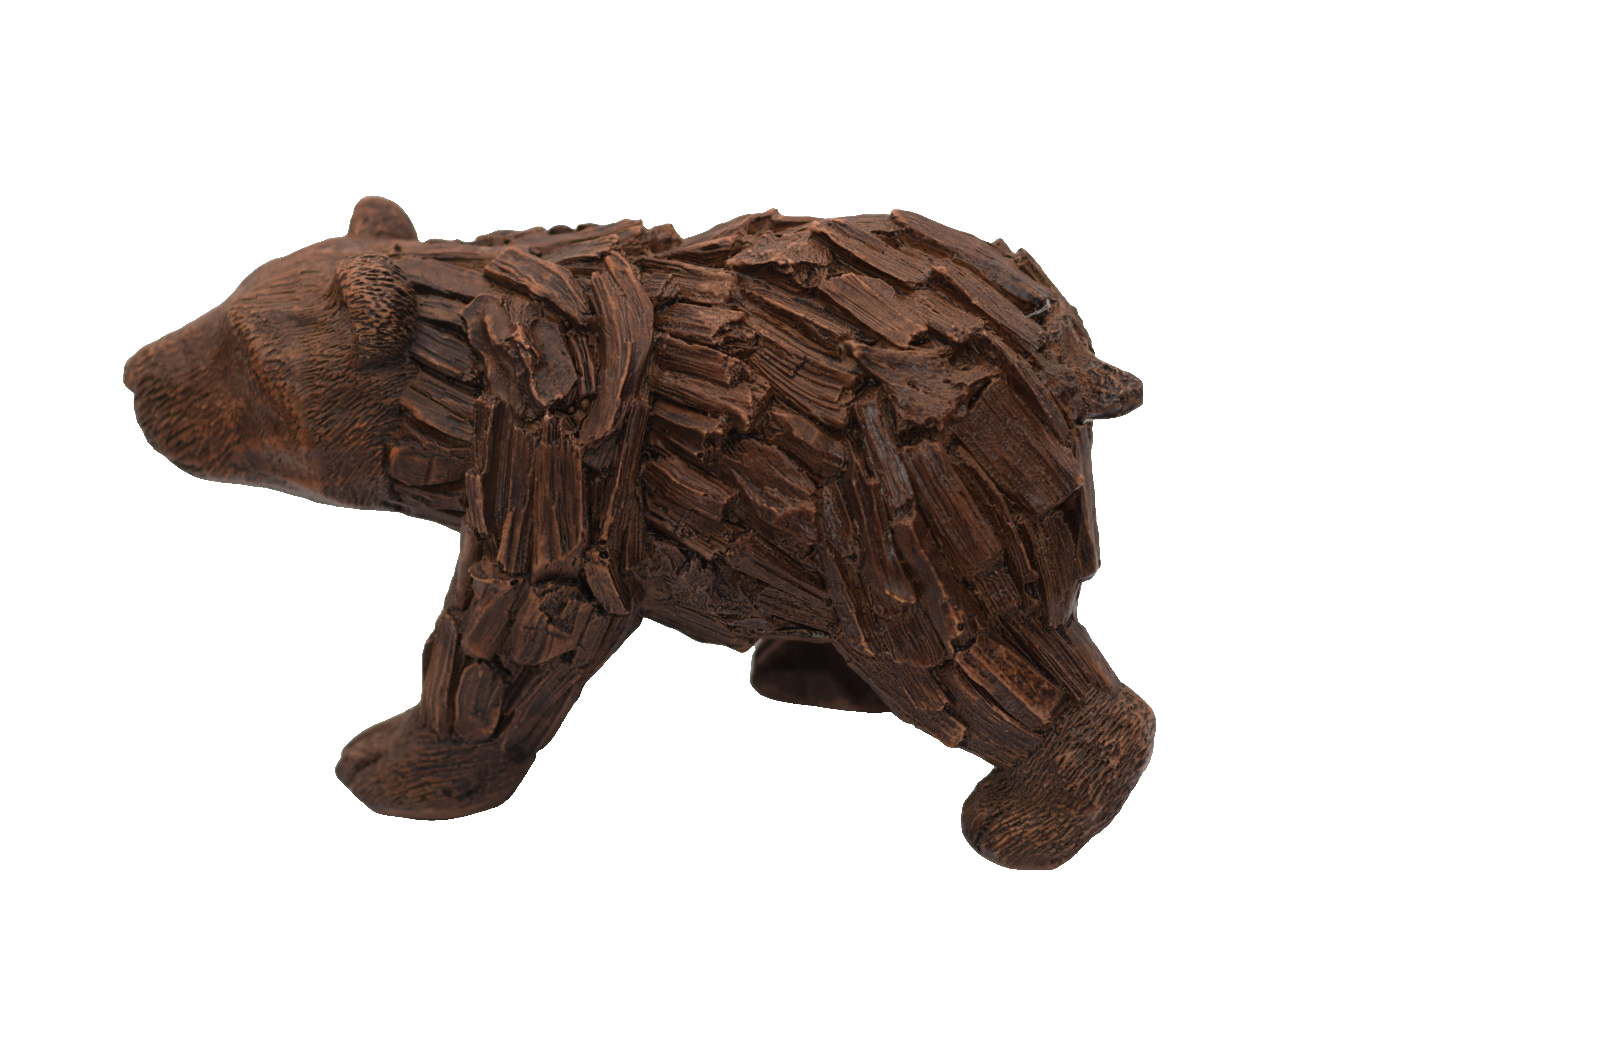

In [ ]:
import json, zipfile
from PIL import Image

if not os.path.exists(f'{DATA}/transforms.json'):
    zipfile.ZipFile(DATA_ZIP).extractall('/content/data')

meta = json.load(open(f'{DATA}/transforms.json'))
images = sorted(os.listdir(f'{DATA}/images'))
first = Image.open(f"{DATA}/{meta['frames'][0]['file_path']}")
print(len(meta['frames']), 'frames |', len(images), 'images |', meta['w'], 'x', meta['h'], '|', first.mode)
assert len(meta['frames']) == len(images) == 87
assert first.mode == 'RGBA' and first.size == (meta['w'], meta['h'])
assert meta.get('ply_file_path') == 'sparse_pc.ply' and os.path.exists(f'{DATA}/sparse_pc.ply')
first

## 6. Helpers
`sh()` streams a command's output, appends it to a log file and raises if it fails.

In [ ]:
import glob, subprocess, sys

def sh(cmd, log):
    print('$', cmd, flush=True)
    with open(log, 'a') as f, subprocess.Popen(cmd, shell=True, text=True, bufsize=1,
                                               stdout=subprocess.PIPE, stderr=subprocess.STDOUT) as p:
        f.write(f'$ {cmd}\n')
        for line in p.stdout:
            sys.stdout.write(line)
            f.write(line)
    if p.returncode:
        raise RuntimeError(f'exit code {p.returncode} — see {log}')

def train_cmd(out_dir, timestamp, iters, resume_dir=None):
    # NB: ns-train runs `--max-num-iterations` steps *after* the loaded checkpoint, not up to it.
    cmd = (f'ns-train nerfacto --data {DATA} --output-dir {out_dir} --experiment-name bear-mask '
           f'--timestamp {timestamp} --vis tensorboard --max-num-iterations {iters} '
           f'--steps-per-save 2000 --mixed-precision False --save-only-latest-checkpoint False --pipeline.model.background-color white ')
    if resume_dir:
        cmd += f'--load-dir {resume_dir} '
    return cmd + 'nerfstudio-data --downscale-factor 1 --eval-mode interval --eval-interval 8'

def run_dir(out_dir, timestamp):
    return f'{out_dir}/bear-mask/nerfacto/{timestamp}'

def checkpoints(run):
    return sorted(glob.glob(f'{run}/nerfstudio_models/step-*.ckpt'))

def ckpt_step(path):
    return int(os.path.basename(path)[5:-5])   # step-000029999.ckpt -> 29999

## 7. Smoke test (500 iterations)
Checks the whole chain (training, checkpointing, evaluation) on a short run before the full job.

In [ ]:
TEST_LOG = f'{LOG_DIR}/test_train.log'
open(TEST_LOG, 'w').close()   # fresh log on every attempt
sh(train_cmd(TEST_OUT, 'test', 500), TEST_LOG)

test_run = run_dir(TEST_OUT, 'test')
assert checkpoints(test_run), 'no checkpoint written'
print('checkpoint:', checkpoints(test_run)[-1])

sh(f'ns-eval --load-config {test_run}/config.yml --output-path {test_run}/eval.json', f'{LOG_DIR}/test_eval.log')
print(json.load(open(f'{test_run}/eval.json'))['results'])

$ ns-train nerfacto --data /content/data/bear-mask --output-dir /content/test_runs --experiment-name bear-mask --timestamp test --vis tensorboard --max-num-iterations 500 --steps-per-save 2000 --mixed-precision False --save-only-latest-checkpoint False --pipeline.model.background-color white nerfstudio-data --downscale-factor 1 --eval-mode interval --eval-interval 8
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
I0000 00:00:1795012274.137426    7220 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795012274.210638    7220 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operati

## 8. Full training (30,000 iterations)
Roughly 1–3 h depending on GPU and whether tiny-cuda-nn is installed.
Checkpoints are written to Drive every 2,000 steps. If the runtime disconnects, re-run sections 3–6 and
then this cell. It resumes from the latest checkpoint and trains only the remaining steps. Once training is
complete, re-running this cell does nothing.

In [ ]:
ITERS = 30000
RUN = run_dir(OUT, 'full')
done = checkpoints(RUN)
start = ckpt_step(done[-1]) + 1 if done else 0

if start >= ITERS:
    print('already trained to step', start - 1)
else:
    print(f'resuming from step {start}' if done else 'training from scratch')
    sh(train_cmd(OUT, 'full', ITERS - start, f'{RUN}/nerfstudio_models' if done else None),
       f'{LOG_DIR}/full_train.log')

last = checkpoints(RUN)[-1]
print('final checkpoint:', last)
assert ckpt_step(last) == ITERS - 1, 'training stopped before the last step'

Streaming output truncated to the last 5000 lines.
26440 (88.13%)      275.014 ms           16 m, 19 s           16.84 K                                    


Step (% Done)       Train Iter (time)    ETA (time)           Train Rays / Sec     Test Rays / Sec       
-------------------------------------------------------------------------------------------------------- 
26360 (87.87%)      290.419 ms           17 m, 37 s           16.33 K                                    
26370 (87.90%)      274.916 ms           16 m, 37 s           16.91 K                                    
26380 (87.93%)      274.280 ms           16 m, 32 s           16.87 K                                    
26390 (87.97%)      288.928 ms           17 m, 23 s           16.41 K                                    
26400 (88.00%)      273.337 ms           16 m, 24 s           17.00 K                                    
26410 (88.03%)      273.906 ms           16 m, 23 s           16.91 K                              

## 9. Evaluate on the held-out images
`ns-eval` reports PSNR/SSIM/LPIPS averaged over the 11 eval views. For each view it saves a
side-by-side **ground truth | render** image (`eval_img_XXXX.png`).

In [ ]:
EVAL_DIR = f'{RUN}/eval'
sh(f'ns-eval --load-config {RUN}/config.yml --output-path {EVAL_DIR}/metrics.json '
   f'--render-output-path {EVAL_DIR}/comparisons', f'{LOG_DIR}/eval.log')

results = json.load(open(f'{EVAL_DIR}/metrics.json'))['results']
for k, v in results.items():
    print(f'{k:>16}: {v:.4f}')
comparisons = sorted(glob.glob(f'{EVAL_DIR}/comparisons/eval_img_*.png'))
assert len(comparisons) == 11, len(comparisons)

# A model that diverged (NaN weights) renders only the white background: PSNR ~9. Healthy runs here are ~25+.
assert results['psnr'] > 15, (f"PSNR {results['psnr']:.1f}: the model collapsed during training. "
                              'Check the training curves in section 10 for where the loss stops.')

# Training kept every checkpoint in case it diverged late. The final model is healthy, so drop the rest
# (~240 MB each on Drive).
for p in checkpoints(RUN)[:-1]:
    os.remove(p)
print('kept', checkpoints(RUN))

$ ns-eval --load-config /content/drive/MyDrive/3d-reconstruction/results/nerfacto/bear-mask/nerfacto/full/config.yml --output-path /content/drive/MyDrive/3d-reconstruction/results/nerfacto/bear-mask/nerfacto/full/eval/metrics.json --render-output-path /content/drive/MyDrive/3d-reconstruction/results/nerfacto/bear-mask/nerfacto/full/eval/comparisons
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
I0000 00:00:1795025938.894345   66173 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795025938.967167   66173 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the

eval_img_0000.png — left: ground truth, right: render


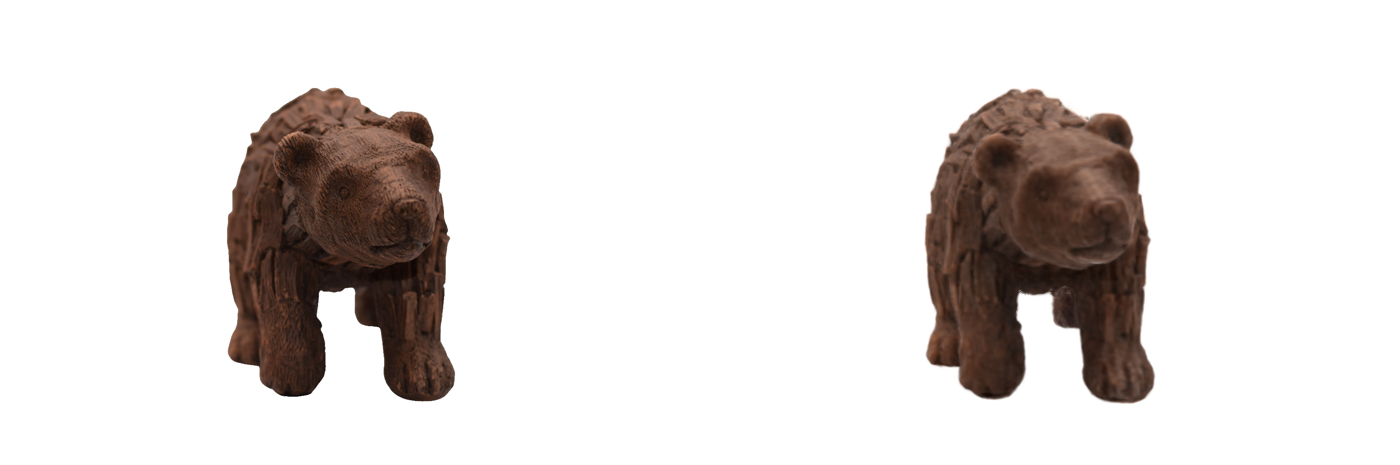

eval_img_0001.png — left: ground truth, right: render


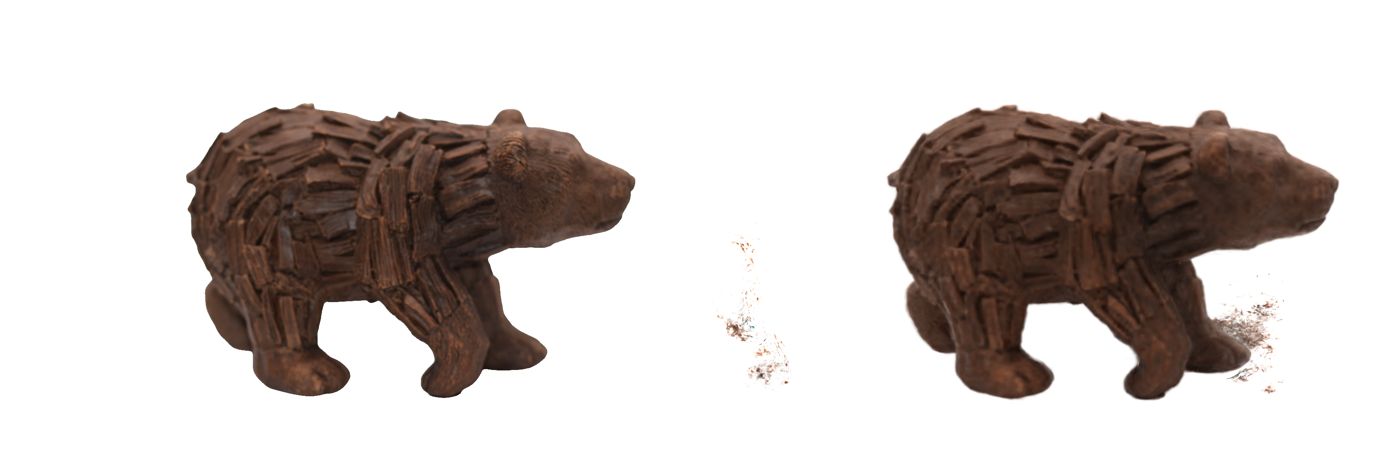

eval_img_0002.png — left: ground truth, right: render


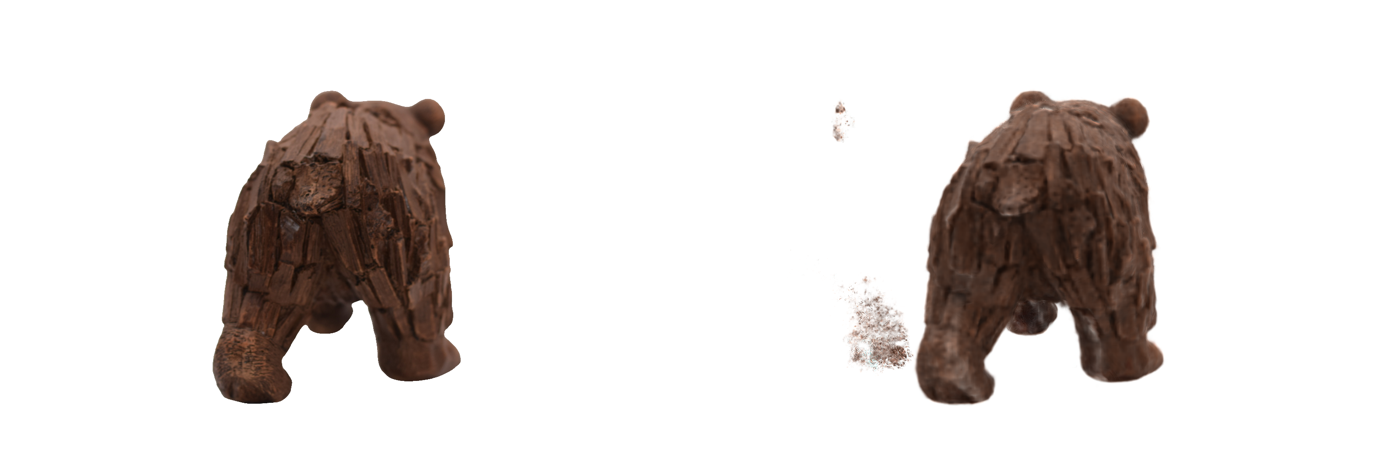

eval_img_0003.png — left: ground truth, right: render


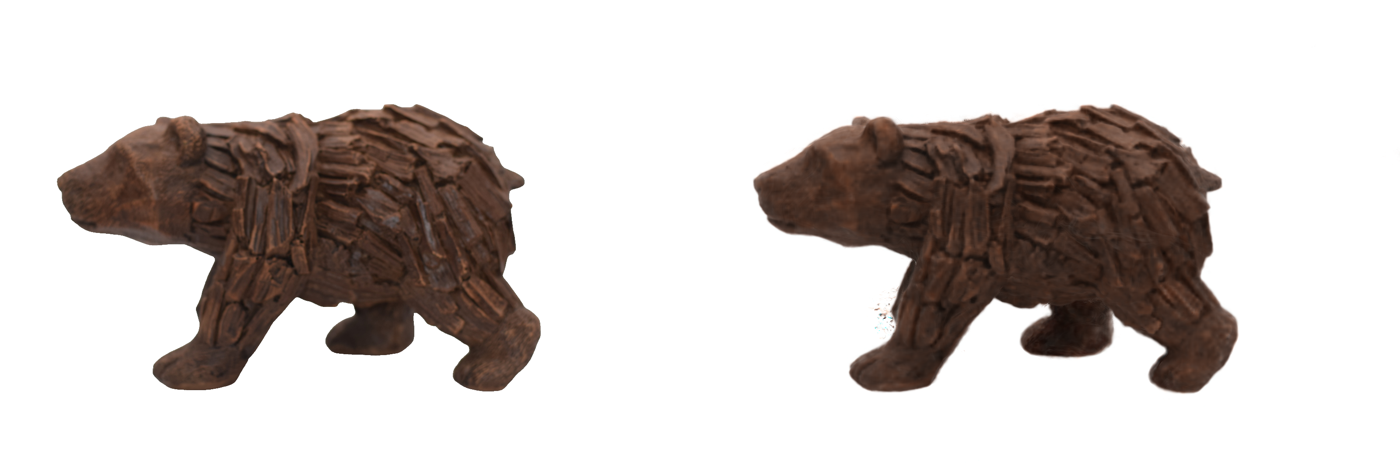

In [ ]:
from IPython.display import display
for path in comparisons[:4]:
    print(os.path.basename(path), '— left: ground truth, right: render')
    im = Image.open(path)
    im.thumbnail((1400, 1400))
    display(im)

## 10. Training curves
Exports every TensorBoard scalar to CSV and plots the loss and PSNR curves. If training was resumed, steps
logged after the last checkpoint of the interrupted run are replaced by the resumed run's values.

['ETA (time)', 'Eval Images Metrics Dict (all images)/fps', 'Eval Images Metrics Dict (all images)/lpips', 'Eval Images Metrics Dict (all images)/num_rays_per_sec', 'Eval Images Metrics Dict (all images)/psnr', 'Eval Images Metrics Dict (all images)/ssim', 'Eval Images Metrics/lpips', 'Eval Images Metrics/num_rays', 'Eval Images Metrics/psnr', 'Eval Images Metrics/ssim', 'Eval Loss', 'Eval Loss Dict/rgb_loss', 'Eval Metrics Dict/camera_opt_rotation_max', 'Eval Metrics Dict/camera_opt_rotation_mean', 'Eval Metrics Dict/camera_opt_translation_max', 'Eval Metrics Dict/camera_opt_translation_mean', 'Eval Metrics Dict/psnr', 'GPU Memory (MB)', 'Test Rays / Sec', 'Train Iter (time)', 'Train Loss', 'Train Loss Dict/camera_opt_regularizer', 'Train Loss Dict/distortion_loss', 'Train Loss Dict/interlevel_loss', 'Train Loss Dict/rgb_loss', 'Train Metrics Dict/camera_opt_rotation_max', 'Train Metrics Dict/camera_opt_rotation_mean', 'Train Metrics Dict/camera_opt_translation_max', 'Train Metrics Di

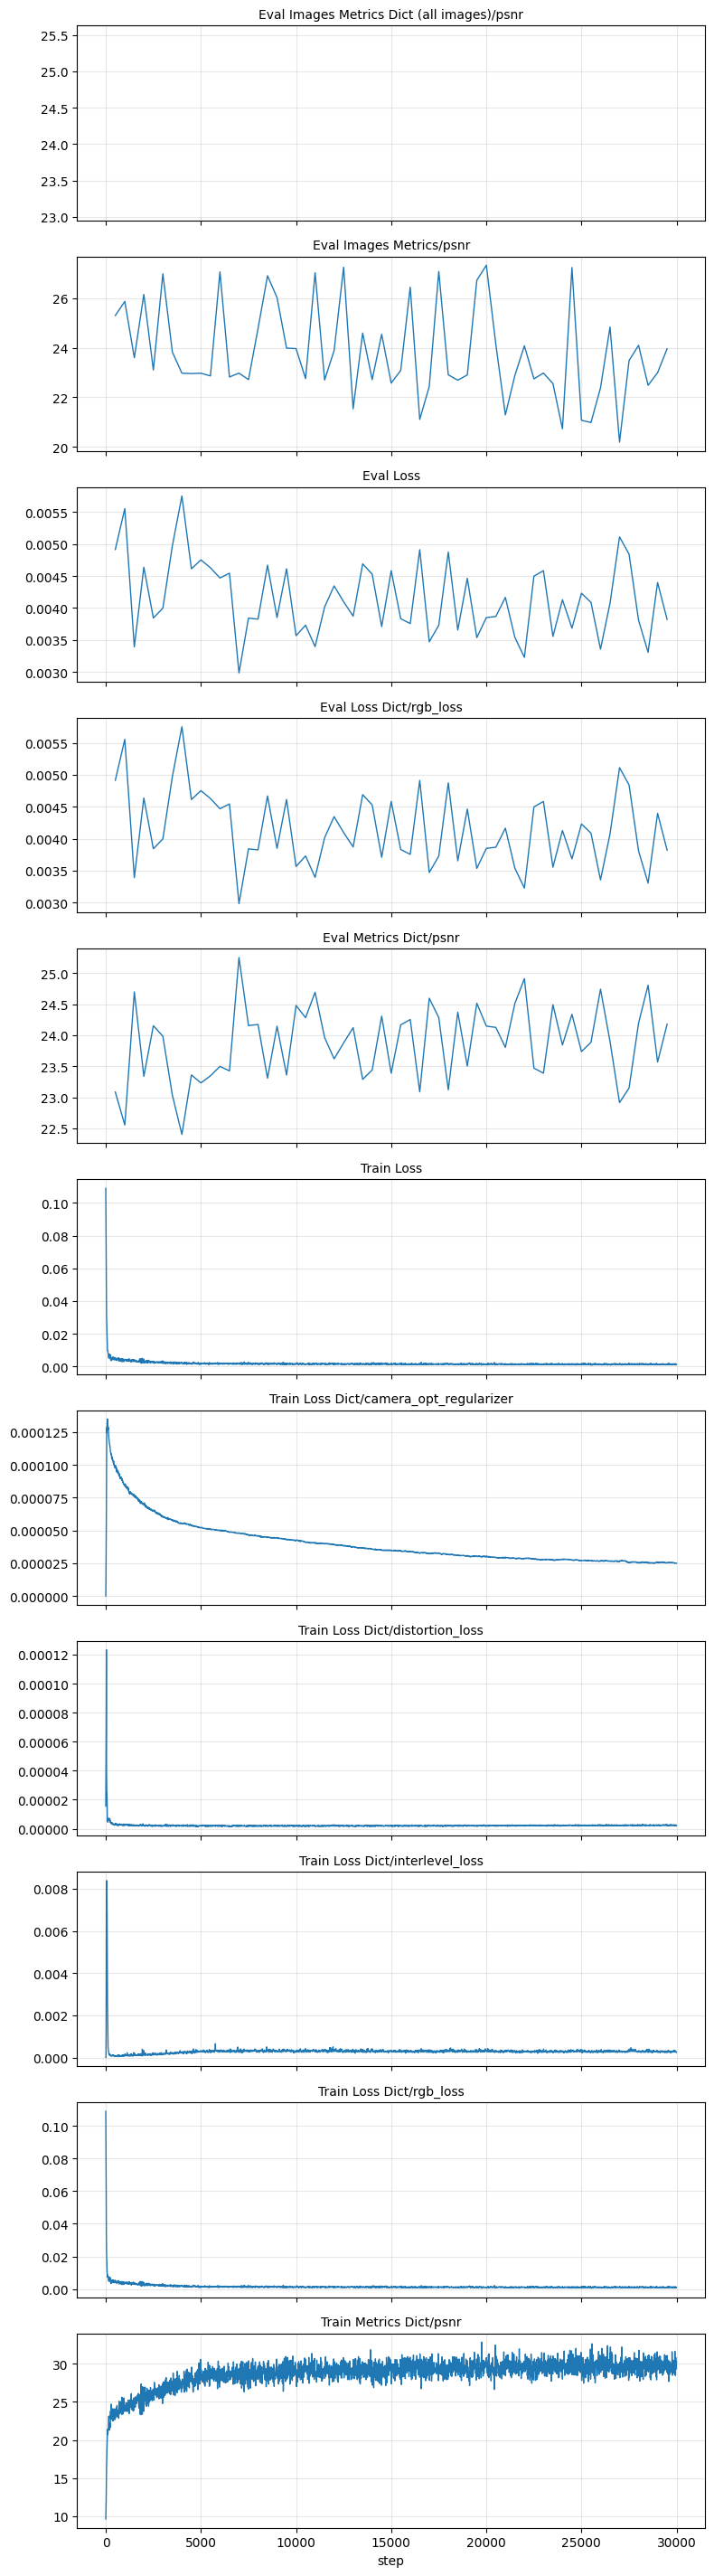

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

ea = EventAccumulator(RUN, size_guidance={'scalars': 0})
ea.Reload()
rows = [(tag, e.wall_time, e.step, e.value) for tag in ea.Tags()['scalars'] for e in ea.Scalars(tag)]
scalars = (pd.DataFrame(rows, columns=['tag', 'wall_time', 'step', 'value'])
           .sort_values('wall_time').drop_duplicates(['tag', 'step'], keep='last')
           .sort_values(['tag', 'step']).drop(columns='wall_time'))
os.makedirs(f'{RUN}/metrics', exist_ok=True)
scalars.to_csv(f'{RUN}/metrics/training_scalars.csv', index=False)
print(sorted(scalars.tag.unique()))

tags = [t for t in scalars.tag.unique() if any(s in t.lower() for s in ('loss', 'psnr'))]
assert tags, 'no loss/psnr scalars found'
fig, axes = plt.subplots(len(tags), 1, figsize=(8, 2.6 * len(tags)), sharex=True, squeeze=False)
axes = axes[:, 0]
for ax, tag in zip(axes, tags):
    d = scalars[scalars.tag == tag]
    ax.plot(d.step, d.value, lw=1)
    ax.set_title(tag, fontsize=10)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel('step')
fig.tight_layout()
fig.savefig(f'{RUN}/metrics/training_curves.png', dpi=150)

## 11. Fly-through video
Interpolates between the training camera poses and renders at half resolution.

In [ ]:
VIDEO = f'{RUN}/renders/interpolate.mp4'
sh(f'ns-render interpolate --load-config {RUN}/config.yml --output-path {VIDEO} '
   f'--pose-source train --order-poses True --interpolation-steps 3 --frame-rate 24 --downscale-factor 2',
   f'{LOG_DIR}/render.log')
assert os.path.getsize(VIDEO) > 0

# Half resolution is 800x531. With an odd dimension, mediapy encodes H.264 4:4:4, which browsers can't play
# (blank player). Re-encode a browser-friendly copy: even size, yuv420p.
WEB = VIDEO.replace('.mp4', '_web.mp4')
sh(f'ffmpeg -y -loglevel error -i "{VIDEO}" -vf "scale=trunc(iw/2)*2:trunc(ih/2)*2" '
   f'-c:v libx264 -pix_fmt yuv420p -crf 18 -movflags +faststart "{WEB}"', f'{LOG_DIR}/render.log')

from IPython.display import Video
Video(WEB, embed=True, width=800)

$ ns-render interpolate --load-config /content/drive/MyDrive/3d-reconstruction/results/nerfacto/bear-mask/nerfacto/full/config.yml --output-path /content/drive/MyDrive/3d-reconstruction/results/nerfacto/bear-mask/nerfacto/full/renders/interpolate.mp4 --pose-source train --order-poses True --interpolation-steps 3 --frame-rate 24 --downscale-factor 2
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
I0000 00:00:1795026639.676526   69323 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795026639.746989   69323 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the

## 12. Export a point cloud
Samples the trained field into a coloured point cloud (`point_cloud.ply`) that you can compare with COLMAP's
`fused.ply`. Nerfacto doesn't predict normals by default, so normals are estimated with Open3D.

In [ ]:
EXPORT = f'{RUN}/export'
sh(f'ns-export pointcloud --load-config {RUN}/config.yml --output-dir {EXPORT} '
   f'--num-points 1000000 --remove-outliers True --normal-method open3d', f'{LOG_DIR}/export.log')
assert os.path.exists(f'{EXPORT}/point_cloud.ply')

$ ns-export pointcloud --load-config /content/drive/MyDrive/3d-reconstruction/results/nerfacto/bear-mask/nerfacto/full/config.yml --output-dir /content/drive/MyDrive/3d-reconstruction/results/nerfacto/bear-mask/nerfacto/full/export --num-points 1000000 --remove-outliers True --normal-method open3d
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
I0000 00:00:1795029623.154441   82351 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795029623.223325   82351 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FM

## 13. What was saved to Drive

In [ ]:
for dirpath, _, files in sorted(os.walk(OUT)):
    for name in sorted(files):
        p = os.path.join(dirpath, name)
        if 'comparisons' not in p:
            print(f'{os.path.getsize(p) / 1e6:9.1f} MB  {os.path.relpath(p, OUT)}')
print(len(comparisons), 'comparison images in', f'{EVAL_DIR}/comparisons')

      0.0 MB  bear-mask/nerfacto/full/config.yml
      0.0 MB  bear-mask/nerfacto/full/dataparser_transforms.json
    279.1 MB  bear-mask/nerfacto/full/events.out.tfevents.1795013124.6fe8ee708edd.10840.0
      0.0 MB  bear-mask/nerfacto/full/eval/metrics.json
     27.1 MB  bear-mask/nerfacto/full/export/point_cloud.ply
      0.5 MB  bear-mask/nerfacto/full/metrics/training_curves.png
     10.3 MB  bear-mask/nerfacto/full/metrics/training_scalars.csv
    242.9 MB  bear-mask/nerfacto/full/nerfstudio_models/step-000029999.ckpt
      0.5 MB  bear-mask/nerfacto/full/renders/interpolate.mp4
      0.8 MB  bear-mask/nerfacto/full/renders/interpolate_web.mp4
      0.1 MB  logs/eval.log
      0.0 MB  logs/export.log
      8.0 MB  logs/full_train.log
      0.0 MB  logs/render.log
      0.1 MB  logs/tcnn_build.log
      0.1 MB  logs/test_eval.log
      0.1 MB  logs/test_train.log
11 comparison images in /content/drive/MyDrive/3d-reconstruction/results/nerfacto/bear-mask/nerfacto/full/eval/comparis